In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/penguins.csv')

# Display the first 5 rows
display(df.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
# Drop the 'island' and 'sex' columns
df = df.drop(columns=['island', 'sex'])

# Display the updated DataFrame
display(df.head())

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
3,Adelie,NaN,NaN,NaN,NaN
4,Adelie,36.7,19.3,193.0,3450.0


In [ ]:
df.shape

(344, 5)

In [ ]:
# Calculate the number of rows with at least one null value
null_rows = df[df.isnull().any(axis=1)]
num_null_rows = len(null_rows)

print(f"Total number of rows with null values: {num_null_rows}")
print("\nRows containing null values:")
display(null_rows)

Total number of rows with null values: 2

Rows containing null values:


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
3,Adelie,NaN,NaN,NaN,NaN
339,Gentoo,NaN,NaN,NaN,NaN


we droped null rows because they are only 2 rows

In [ ]:
# Drop rows containing null values
df = df.dropna()

# Display new shape and preview
print(f"New shape of the DataFrame: {df.shape}")
display(df.head())

New shape of the DataFrame: (342, 5)


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
4,Adelie,36.7,19.3,193.0,3450.0
5,Adelie,39.3,20.6,190.0,3650.0


In [ ]:
# Calculate and display the number of duplicate rows
duplicates = df[df.duplicated(keep=False)]
print(f"Number of duplicate rows in the dataset: {df.duplicated().sum()}")

if len(duplicates) > 0:
    print("\nDuplicate rows:")
    display(duplicates)
else:
    print("\nNo duplicate rows found.")

Number of duplicate rows in the dataset: 0

No duplicate rows found.


In [ ]:
# Show the number of distinct values in the 'species' column
print("Number of distinct species:", df['species'].nunique())
print("\nDistinct species value counts:")
print(df['species'].value_counts())

Number of distinct species: 3

Distinct species value counts:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


In [ ]:
# Define features (X) and target (y)
X = df.drop('species', axis=1)
y = df['species']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (273, 4)
Shape of X_test: (69, 4)
Shape of y_train: (273,)
Shape of y_test: (69,)


In [ ]:
from sklearn.naive_bayes import GaussianNB

# Initialize Gaussian Naive Bayes classifier
gnb = GaussianNB()

# Fit the model to the training data
gnb.fit(X_train, y_train)

print("Gaussian Naive Bayes model fitted successfully.")

Gaussian Naive Bayes model fitted successfully.


In [ ]:
import pandas as pd

y_pred = gnb.predict(X_test)

# Create a DataFrame to display predicted vs actual values
results_df = pd.DataFrame({
    'Actual': y_test.reset_index(drop=True),
    'Predicted': pd.Series(y_pred)
})

print("First 5 predicted vs actual values:")
display(results_df.head(5))

First 5 predicted vs actual values:


,Actual,Predicted
0,Adelie,Adelie
1,Adelie,Adelie
2,Gentoo,Gentoo
3,Gentoo,Gentoo
4,Chinstrap,Chinstrap


Model Accuracy: 0.9855

Confusion Matrix:
[[30  0  0]
 [ 1 13  0]
 [ 0  0 25]]


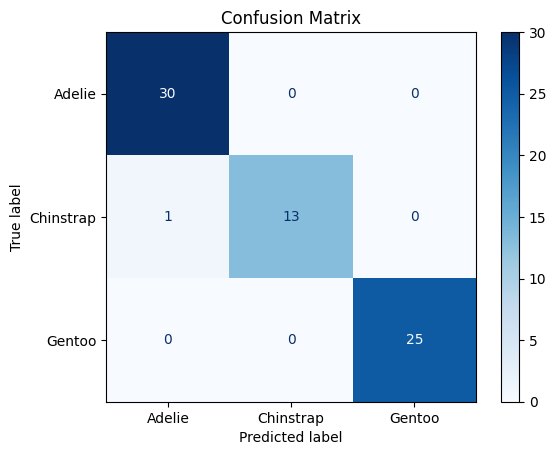

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=gnb.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69



1. Why do we use Gaussian Naive Bayes for these features?
   - We use Gaussian Naive Bayes because the features are numerical and we used gaussirnNB because the numbers are continous
2. Why must test data stay separate when training the model?
   - Test data must stay separate so we can evaluate the model on data it has not seen during training.
3. Explain the accuracy and one mistake shown in the confusion matrix.
   - The model has 98.55% accuracy. There is only one mistake: one Chinstrap penguin was incorrectly predicted as Adelie which might be because the examples on Chinstrap where less than the others.